# 19 · Comparación por horizonte exacto (1–15 días) — protocolo unificado

**Objetivo:** para cada origen `t`, predecir **exclusivamente** `precio_bolsa[t+h]` para `h=1,...,15`, con los mismos orígenes para todos los modelos. Cuatro modelos (SARIMAX semanal, LSTM cuantílica, TFT, GRU Bayesiana), control SARIMAX sin estacionalidad y dos benchmarks.

**Advertencias metodológicas:**
- SARIMAX y TFT emplean covariables **congeladas al origen** como escenario principal, una hipótesis operativa sencilla (no un pronóstico optimizado de las covariables). SARIMAX con covariables futuras realizadas se calcula **solo como escenario oracle**, explícitamente no operativo.
- La GRU utiliza exclusivamente secuencias históricas disponibles hasta el origen; sus intervalos Monte Carlo de pesos pueden infracubrir.
- Los cuantiles obtenidos al **recursar medianas** de LSTM son aproximaciones heurísticas, no cuantiles calibrados de la distribución conjunta multi-paso.
- No se seleccionan hiperparámetros con el test. Se conservan las configuraciones de los experimentos anteriores. La comparación de modelos se presenta como evaluación fuera de muestra, no como inferencia causal de estacionalidad.
- Este notebook **entrena de nuevo** LSTM, TFT (15 horizontes) y GRU; puede tardar. Las predicciones se exportan al finalizar cada bloque para recuperarlas.


In [1]:
# Si es la primera vez que ejecutas este notebook, instala UCT en el entorno tesis-bolsa:
# %pip install uncertainty-toolbox

from pathlib import Path
import os, random, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 333
random.seed(SEED)
np.random.seed(SEED)

def encontrar_raiz_repo():
    actual = Path.cwd().resolve()
    for p in [actual, *actual.parents]:
        if (p / ".git").exists() or ((p / "data" / "processed").exists() and (p / "notebooks").exists()):
            return p
    raise FileNotFoundError("No se encontró la raíz del proyecto tesis-bolsa.")

ROOT = encontrar_raiz_repo()
DATA = ROOT / "data" / "processed"
MODELS = ROOT / "models"
REPORTS = ROOT / "reports" / "comparacion_definitiva_horizontes_exactos"
REPORTS.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

TEST_START = pd.Timestamp("2025-08-01")
TEST_END   = pd.Timestamp("2026-07-31")
HORIZONTES = list(range(1, 16))
COVARIABLES = ["gen_termica", "ONI", "aportes_energia_gwh"]

print("Raíz:", ROOT)
print("Reportes:", REPORTS)
# Desactivar entrenamiento de TFT para depuración rápida solamente: True para resultados completos
EJECUTAR_TFT = True


Raíz: /Users/maguverm/Documents/tesis-bolsa
Reportes: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_definitiva_horizontes_exactos


In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)

# TFT de GluonTS se mantiene en CPU por compatibilidad con la implementación original.
# Permitimos que PyTorch use los núcleos CPU disponibles para ese entrenamiento.
N_CPU = os.cpu_count() or 1
torch.set_num_threads(N_CPU)

if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)
torch.manual_seed(SEED)

print("Dispositivo redes PyTorch:", device)
print("Hilos CPU disponibles para TFT:", N_CPU)

Dispositivo redes PyTorch: mps
Hilos CPU disponibles para TFT: 18


In [3]:
df = pd.read_parquet(DATA / "dataset_consolidado.parquet").copy()
df.index = pd.to_datetime(df.index)
df = df.sort_index()

faltantes = [c for c in ["precio_bolsa", *COVARIABLES] if c not in df.columns]
if faltantes:
    raise KeyError(f"Faltan columnas necesarias: {faltantes}")

train_df = df[df.index < TEST_START].copy()
test_df  = df[(df.index >= TEST_START) & (df.index <= TEST_END)].copy()

print("Train:", train_df.index.min().date(), "→", train_df.index.max().date(), len(train_df))
print("Test: ", test_df.index.min().date(), "→", test_df.index.max().date(), len(test_df))
assert df.index.is_unique and df.index.is_monotonic_increasing
assert not df[['precio_bolsa',*COVARIABLES]].isna().any().any()
assert (test_df.index.to_series().diff().dropna()==pd.Timedelta(days=1)).all()
assert train_df.index[-1] == test_df.index[0]-pd.Timedelta(days=1)
MAX_H=max(HORIZONTES)
N_ORIGENES=len(test_df)-MAX_H+1
ORIGENES=pd.DatetimeIndex([train_df.index[-1],*test_df.index[:N_ORIGENES-1]])
assert len(ORIGENES)==N_ORIGENES
print('Orígenes comunes:',len(ORIGENES),'desde',ORIGENES[0],'hasta',ORIGENES[-1])


Train: 2013-01-01 → 2025-07-31 4595
Test:  2025-08-01 → 2026-07-31 365
Orígenes comunes: 351 desde 2025-07-31 00:00:00 hasta 2026-07-16 00:00:00


## 1. Formato común y métricas

In [4]:
from sklearn.metrics import r2_score, median_absolute_error, max_error

Z90 = 1.2815515655446004  # cuantil N(0,1) correspondiente a 0.90

def std_equivalente_p10_p90(p10, p90, piso=1e-6):
    p10 = np.asarray(p10, dtype=float)
    p90 = np.asarray(p90, dtype=float)
    return np.maximum((p90 - p10) / (2 * Z90), piso)

def asegurar_intervalos(p10, p50, p90):
    arr = np.vstack([p10, p50, p90]).T
    arr = np.sort(arr, axis=1)
    return arr[:,0], arr[:,1], arr[:,2]

def metricas_puntuales(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {
        "MAE": np.mean(np.abs(y-p)),
        "RMSE": np.sqrt(np.mean((y-p)**2)),
        "MAPE (%)": np.mean(np.abs((y-p)/np.maximum(np.abs(y),1e-8)))*100,
        "sMAPE (%)": np.mean(2*np.abs(y-p)/(np.abs(y)+np.abs(p)+1e-8))*100,
        "R²": r2_score(y,p),
        "MedAE": median_absolute_error(y,p),
        "MaxError": max_error(y,p),
        "Sesgo": np.mean(p-y),
    }

def metricas_intervalo(y, p10, p90):
    y = np.asarray(y,float); p10=np.asarray(p10,float); p90=np.asarray(p90,float)
    dentro = (y >= p10) & (y <= p90)
    ancho = p90-p10
    # Interval score central 80%, alpha=0.20
    alpha = 0.20
    score = ancho + (2/alpha)*(p10-y)*(y<p10) + (2/alpha)*(y-p90)*(y>p90)
    return {
        "Cobertura 80% (%)": dentro.mean()*100,
        "Ancho P10-P90": ancho.mean(),
        "Interval score 80%": score.mean(),
    }

def normalizar_salida(modelo, h, fechas, real, pred, p10, p50, p90, std=None, origen=""):
    p10,p50,p90 = asegurar_intervalos(p10,p50,p90)
    if std is None:
        std = std_equivalente_p10_p90(p10,p90)
    z = pd.DataFrame({
        "Modelo": modelo, "Horizonte": h, "real": np.asarray(real,float),
        "pred": np.asarray(pred,float), "p10": p10, "p50": p50, "p90": p90,
        "std": np.maximum(np.asarray(std,float),1e-6),
        "Origen_incertidumbre": origen
    }, index=pd.to_datetime(fechas))
    z.index.name = "fecha"
    return z.sort_index()
def registrar_exacto(modelo,h,origenes,fechas,real,pred,p10,p50,p90,std=None,descripcion=''):
    origenes=pd.DatetimeIndex(origenes); fechas=pd.DatetimeIndex(fechas)
    assert len(origenes)==len(ORIGENES)==len(fechas)
    assert origenes.equals(ORIGENES),f'Orígenes distintos: {modelo}, h={h}'
    assert ((fechas-origenes).days==h).all(),f'Horizonte incorrecto: {modelo}, h={h}'
    z=normalizar_salida(modelo,h,fechas,real,pred,p10,p50,p90,std,descripcion)
    z['origen']=origenes.values
    assert z.index.is_unique and np.isfinite(z[['real','pred','p10','p90']].values).all()
    resultados[(modelo,h)]=z

def guardar_predicciones(nombre):
    p=REPORTS/f'predicciones_{nombre}.parquet'
    pd.concat([z.reset_index() for z in resultados.values()],ignore_index=True).to_parquet(p,index=False)
    print('Guardado:',p)

resultados={}


## 2. SARIMAX semanal y sin semana: ajuste con verificación de convergencia y rolling origin exacto

In [5]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from scipy.stats import norm
import time

FITS={}; ESTADOS_FIT=[]
for nombre,seasonal in [('SARIMAX',(1,0,1,7)),('SARIMAX sin semana',(0,0,0,0))]:
    mod=SARIMAX(train_df['precio_bolsa'],exog=train_df[COVARIABLES],
        order=(2,0,2),seasonal_order=seasonal,
        enforce_stationarity=False,enforce_invertibility=False)
    candidatos=[]
    for metodo in ['lbfgs','powell']:
        try:
            inicio=time.time()
            ajuste=mod.fit(disp=False,method=metodo,maxiter=700)
            ok=bool(ajuste.mle_retvals.get('converged',False))
            candidatos.append((ok,float(ajuste.llf),ajuste,metodo))
            print(nombre,metodo,'convergencia',ok,'AIC',round(ajuste.aic,2),
                  'segundos',round(time.time()-inicio,1))
            if ok: break
        except Exception as exc:
            print('Fallo de optimización:',nombre,metodo,repr(exc))
    convergidos=[c for c in candidatos if c[0]]
    if not convergidos:
        raise RuntimeError(f'{nombre}: ningún optimizador convergió. No continuar con inferencias; revisar especificación/escala.')
    mejor=max(convergidos,key=lambda c:c[1])
    FITS[nombre]=mejor[2]
    ESTADOS_FIT.append({'modelo':nombre,'metodo':mejor[3],'convergencia':True,'AIC':mejor[2].aic})

pd.DataFrame(ESTADOS_FIT).to_csv(REPORTS/'diagnostico_convergencia.csv',index=False)

def sarimax_exacto(fit,modelo,escenario):
    estado=fit
    acumulado={h:[] for h in HORIZONTES}
    for k,origen in enumerate(ORIGENES):
        futuro=test_df.iloc[k:k+MAX_H]
        if escenario=='congeladas':
            pasado=(train_df.iloc[-1] if k==0 else test_df.iloc[k-1])[COVARIABLES]
            xf=pd.DataFrame(np.tile(pasado.to_numpy(dtype=float),(MAX_H,1)),
                            index=futuro.index,columns=COVARIABLES)
        elif escenario=='oracle':
            xf=futuro[COVARIABLES]
        else: raise ValueError(escenario)
        fc=estado.get_forecast(steps=MAX_H,exog=xf)
        mu=np.asarray(fc.predicted_mean,dtype=float)
        se=np.asarray(fc.se_mean,dtype=float)
        for h in HORIZONTES:
            j=h-1
            acumulado[h].append((origen,futuro.index[j],float(futuro['precio_bolsa'].iloc[j]),
                    mu[j],mu[j]-1.2815515655*se[j],mu[j],mu[j]+1.2815515655*se[j],se[j]))
        if k<len(ORIGENES)-1:
            obs=test_df.iloc[k:k+1]
            estado=estado.append(obs['precio_bolsa'],exog=obs[COVARIABLES],refit=False)
        if (k+1)%100==0:print(modelo,escenario,k+1,'/',len(ORIGENES))
    for h,filas in acumulado.items():
        z=pd.DataFrame(filas,columns=['origen','fecha','real','pred','p10','p50','p90','std'])
        registrar_exacto(modelo if escenario=='congeladas' else modelo+' [oracle]',h,
            z.origen,z.fecha,z.real,z.pred,z.p10,z.p50,z.p90,z['std'],
            'SARIMAX distribución gaussiana, '+escenario)

for nombre,fit in FITS.items():
    sarimax_exacto(fit,nombre,'congeladas')
    sarimax_exacto(fit,nombre,'oracle')
guardar_predicciones('sarimax')


/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMAX lbfgs convergencia False AIC 52392.66 segundos 1.5
SARIMAX powell convergencia True AIC 50601.08 segundos 2.7


/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMAX sin semana lbfgs convergencia False AIC 51112.43 segundos 0.3
SARIMAX sin semana powell convergencia True AIC 50682.3 segundos 0.4
SARIMAX congeladas 100 / 351
SARIMAX congeladas 200 / 351
SARIMAX congeladas 300 / 351
SARIMAX oracle 100 / 351
SARIMAX oracle 200 / 351
SARIMAX oracle 300 / 351
SARIMAX sin semana congeladas 100 / 351
SARIMAX sin semana congeladas 200 / 351
SARIMAX sin semana congeladas 300 / 351
SARIMAX sin semana oracle 100 / 351
SARIMAX sin semana oracle 200 / 351
SARIMAX sin semana oracle 300 / 351
Guardado: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_definitiva_horizontes_exactos/predicciones_sarimax.parquet


## 3. LSTM cuantílica: entrenamiento histórico y predicción recursiva desde cada origen

In [6]:
from sklearn.preprocessing import MinMaxScaler

train = train_df["precio_bolsa"]
test = test_df["precio_bolsa"]
VENTANA=30

scaler_lstm=MinMaxScaler()
train_scaled=scaler_lstm.fit_transform(train.values.reshape(-1,1))
test_scaled=scaler_lstm.transform(test.values.reshape(-1,1))

def crear_ventanas(data, ventana=VENTANA):
    X,y=[],[]
    for i in range(len(data)-ventana):
        X.append(data[i:i+ventana]); y.append(data[i+ventana])
    return np.array(X),np.array(y)

X_train,y_train=crear_ventanas(train_scaled)
loader=DataLoader(
    TensorDataset(torch.FloatTensor(X_train),torch.FloatTensor(y_train)),
    batch_size=32,shuffle=True
)

class ModeloLSTMQuantile(nn.Module):
    def __init__(self,input_size=1,hidden_size=64,num_layers=2,n_quantiles=3):
        super().__init__()
        self.lstm=nn.LSTM(input_size,hidden_size,num_layers,batch_first=True,dropout=.2)
        self.fc=nn.Linear(hidden_size,n_quantiles)
    def forward(self,x):
        out,_=self.lstm(x)
        return self.fc(out[:,-1,:])

QUANTILES=[.1,.5,.9]
def pinball_loss(pred,true):
    losses=[]
    true=true.squeeze()
    for i,q in enumerate(QUANTILES):
        e=true-pred[:,i]
        losses.append(torch.maximum((q-1)*e,q*e))
    return torch.mean(torch.stack(losses,dim=1).sum(dim=1))

torch.manual_seed(SEED)
modelo_lstm_q=ModeloLSTMQuantile().to(device)
opt=torch.optim.Adam(modelo_lstm_q.parameters(),lr=.001)

EPOCHS_LSTM_Q=50
for epoch in range(EPOCHS_LSTM_Q):
    modelo_lstm_q.train(); acc=0
    for xb,yb in loader:
        xb,yb=xb.to(device),yb.to(device)
        opt.zero_grad()
        loss=pinball_loss(modelo_lstm_q(xb),yb)
        loss.backward(); opt.step(); acc+=loss.item()
    if (epoch+1)%10==0:
        print(f"LSTM-Q epoch {epoch+1}/{EPOCHS_LSTM_Q} loss={acc/len(loader):.6f}")

LSTM-Q epoch 10/50 loss=0.013261
LSTM-Q epoch 20/50 loss=0.012622
LSTM-Q epoch 30/50 loss=0.012379
LSTM-Q epoch 40/50 loss=0.012055
LSTM-Q epoch 50/50 loss=0.011945


In [7]:
# Cada origen usa SOLO precios observados hasta t; después recursa con la mediana.
# Los cuantiles a h>1 son aproximaciones plug-in, NO cuantiles conjuntos calibrados.
modelo_lstm_q.eval()
hist=np.concatenate([train_scaled.flatten(),test_scaled.flatten()])
nt=len(train_scaled)
acum={h:[] for h in HORIZONTES}
with torch.no_grad():
    for k,origen in enumerate(ORIGENES):
        sec=list(hist[nt+k-VENTANA:nt+k].astype(float))
        for h in HORIZONTES:
            x=torch.tensor(np.asarray(sec[-VENTANA:],dtype=np.float32).reshape(1,VENTANA,1),device=device)
            q=np.sort(modelo_lstm_q(x).cpu().numpy().flatten())
            vals=scaler_lstm.inverse_transform(q.reshape(-1,1)).flatten()
            fecha=test_df.index[k+h-1]
            acum[h].append((origen,fecha,float(test_df['precio_bolsa'].iloc[k+h-1]),
                             vals[1],vals[0],vals[1],vals[2]))
            sec.append(float(q[1]))
for h,filas in acum.items():
    z=pd.DataFrame(filas,columns=['origen','fecha','real','pred','p10','p50','p90'])
    registrar_exacto('LSTM cuantílica',h,z.origen,z.fecha,z.real,z.pred,z.p10,z.p50,z.p90,
        descripcion='Cuantiles plug-in con mediana recursiva; calibración multi-paso no garantizada')
guardar_predicciones('lstm')


Guardado: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_definitiva_horizontes_exactos/predicciones_lstm.parquet


## 4. TFT: entrenar un modelo por horizonte y evaluar SOLO el paso h desde cada origen

In [8]:
from sklearn.preprocessing import StandardScaler
from gluonts.dataset.common import ListDataset
from gluonts.torch.model.tft import TemporalFusionTransformerEstimator

FREQ='D'
scaler_cov=StandardScaler().fit(train_df[COVARIABLES])
scaled=df.copy()
scaled[COVARIABLES]=scaler_cov.transform(df[COVARIABLES])
train_scaled_cov=scaled.loc[train_df.index]
train_ds=ListDataset([{
    'target':train_scaled_cov['precio_bolsa'].values,
    'start':train_scaled_cov.index[0],
    'feat_dynamic_real':train_scaled_cov[COVARIABLES].values.T,
}],freq=FREQ)

if EJECUTAR_TFT:
    for h in HORIZONTES:
        print('Entrenando TFT horizonte',h)
        estimator=TemporalFusionTransformerEstimator(
            freq=FREQ,prediction_length=h,context_length=730,
            trainer_kwargs={'max_epochs':50,'accelerator':'cpu','enable_progress_bar':False})
        predictor=estimator.train(train_ds)
        filas=[]
        for k,origen in enumerate(ORIGENES):
            # target: observado hasta el origen; covariables futuras congeladas al origen.
            observado=scaled.loc[:origen]
            last_cov=observado[COVARIABLES].iloc[-1].to_numpy(dtype=float)
            futuras=pd.DataFrame(np.tile(last_cov,(h,1)),
                index=test_df.index[k:k+h],columns=COVARIABLES)
            cov=pd.concat([observado[COVARIABLES],futuras])
            ds=ListDataset([{
                'target':observado['precio_bolsa'].values,
                'start':observado.index[0],
                'feat_dynamic_real':cov.values.T,
            }],freq=FREQ)
            fc=next(iter(predictor.predict(ds)))
            j=h-1
            media=float(np.asarray(fc.mean)[j]); q10=float(np.asarray(fc.quantile(.1))[j]);
            q50=float(np.asarray(fc.quantile(.5))[j]); q90=float(np.asarray(fc.quantile(.9))[j])
            filas.append((origen,test_df.index[k+j],float(test_df['precio_bolsa'].iloc[k+j]),
                          media,q10,q50,q90))
            if (k+1)%100==0:print('TFT h',h,'orígenes',k+1,'/',len(ORIGENES))
        z=pd.DataFrame(filas,columns=['origen','fecha','real','pred','p10','p50','p90'])
        registrar_exacto('TFT + covariables',h,z.origen,z.fecha,z.real,z.pred,z.p10,z.p50,z.p90,
            descripcion='Cuantiles nativos TFT; covariables futuras congeladas')
        guardar_predicciones('tft_parcial')
else:
    print('TFT desactivado: las tablas completas exigirán volver a activarlo.')


GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type                           | Params | Mode  | FLOPs  | In sizes                                                                                 | Out sizes                    
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
0 | model | TemporalFusionTransformerModel | 109 K  | train | 59.9 M | [[1, 730], [1, 730], [1, 1], [1, 1], [1, 731, 3], [1, 731, 0], [1, 730, 0], [1, 730, 0]] | [[[1, 1, 9]], [1, 1], [1, 1]]
-----------------------------------------------------------------------------------------------------------

Entrenando TFT horizonte 1


Epoch 0, global step 50: 'train_loss' reached 115.54299 (best 115.54299), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_126/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 46.21592 (best 46.21592), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_126/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 39.24791 (best 39.24791), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_126/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 29.51144 (best 29.51144), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_126/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 28.72343 (best 28.72343), saving model to '/Users/mag

TFT h 1 orígenes 100 / 351
TFT h 1 orígenes 200 / 351
TFT h 1 orígenes 300 / 351


GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type                           | Params | Mode  | FLOPs  | In sizes                                                                                 | Out sizes                    
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
0 | model | TemporalFusionTransformerModel | 109 K  | train | 60.0 M | [[1, 730], [1, 730], [1, 1], [1, 1], [1, 732, 3], [1, 732, 0], [1, 730, 0], [1, 730, 0]] | [[[1, 2, 9]], [1, 1], [1, 1]]
-----------------------------------------------------------------------------------------------------------

...

TFT h 14 orígenes 100 / 351
TFT h 14 orígenes 200 / 351
TFT h 14 orígenes 300 / 351


GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type                           | Params | Mode  | FLOPs  | In sizes                                                                                 | Out sizes                     
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
0 | model | TemporalFusionTransformerModel | 109 K  | train | 62.5 M | [[1, 730], [1, 730], [1, 1], [1, 1], [1, 745, 3], [1, 745, 0], [1, 730, 0], [1, 730, 0]] | [[[1, 15, 9]], [1, 1], [1, 1]]
--------------------------------------------------------------------------------------------------------

Guardado: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_definitiva_horizontes_exactos/predicciones_tft_parcial.parquet
Entrenando TFT horizonte 15


Epoch 0, global step 50: 'train_loss' reached 120.76702 (best 120.76702), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_140/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 76.24468 (best 76.24468), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_140/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 68.23145 (best 68.23145), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_140/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 60.87609 (best 60.87609), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_140/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 58.84689 (best 58.84689), saving model to '/Users/mag

TFT h 15 orígenes 100 / 351
TFT h 15 orígenes 200 / 351
TFT h 15 orígenes 300 / 351
Guardado: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_definitiva_horizontes_exactos/predicciones_tft_parcial.parquet


## 5. GRU Bayesiana: 15 salidas directas con información histórica hasta el origen

In [9]:
from bayesian_torch.models.dnn_to_bnn import dnn_to_bnn, get_kl_loss
import random
from sklearn.preprocessing import StandardScaler

# Configuración escogida en validación en notebook 14. NO se usa test para escogerla.
GRU_LOOKBACK=60
GRU_NEURONAS=32
GRU_LR=5e-4
GRU_DROPOUT=.3
GRU_EPOCHS=6
GRU_N_MC=100

def ejecutar_gru_bayesiana():
    horizontes_gru=HORIZONTES
    random.seed(42); np.random.seed(42); torch.manual_seed(42)
    datos=pd.read_parquet(DATA/'dataset_consolidado.parquet').copy()
    datos.index=pd.to_datetime(datos.index)
    datos=datos.sort_index()
    datos=datos[~datos.index.duplicated(keep='last')].select_dtypes(include=[np.number])
    TARGET='precio_bolsa'
    df=datos
    # Features de calendario y régimen. Todas usan solo información disponible hasta t.
    p=df[TARGET].astype(float)
    df["dow_sin"]=np.sin(2*np.pi*df.index.dayofweek/7)
    df["dow_cos"]=np.cos(2*np.pi*df.index.dayofweek/7)
    df["month_sin"]=np.sin(2*np.pi*(df.index.month-1)/12)
    df["month_cos"]=np.cos(2*np.pi*(df.index.month-1)/12)
    df["fin_semana"]=(df.index.dayofweek>=5).astype(float)
    
    df["precio_ma7"]=p.rolling(7).mean()
    df["precio_ma30"]=p.rolling(30).mean()
    df["precio_std7"]=p.rolling(7).std()
    df["precio_std30"]=p.rolling(30).std()
    df["precio_min30"]=p.rolling(30).min()
    df["precio_max30"]=p.rolling(30).max()
    df["precio_rel_ma7"]=p/df["precio_ma7"]
    df["precio_rel_ma30"]=p/df["precio_ma30"]
    df["precio_z30"]=(p-df["precio_ma30"])/df["precio_std30"].replace(0,np.nan)
    df["precio_cambio1"]=p.pct_change(1)
    df["precio_cambio7"]=p.pct_change(7)
    
    aliases={
     "aportes":["aportes_energia_gwh","aportes_energia","aportes"],
     "gen_termica":["gen_termica","generacion_termica"],
     "demanda":["demanda","demanda_energia"],
     "vol_util":["vol_util","volumen_util","energia_embalsada"]
    }
    for _,opts in aliases.items():
        col=next((x for x in opts if x in df.columns),None)
        if col:
            df[f"{col}_ma7"]=df[col].rolling(7).mean()
            df[f"{col}_ma30"]=df[col].rolling(30).mean()
            df[f"{col}_cambio7"]=df[col].pct_change(7)
    
    df=df.replace([np.inf,-np.inf],np.nan).dropna().copy()
    FEATURES=list(df.columns)
    print("Features:",len(FEATURES))
    print(FEATURES)

    FEATURES=list(df.columns)
    pre=df[df.index<TEST_START].copy()
    test=df[(df.index>=TEST_START)&(df.index<=TEST_END)].copy()
    scaler=StandardScaler().fit(pre[FEATURES])
    spre=pd.DataFrame(scaler.transform(pre[FEATURES]),index=pre.index,columns=FEATURES)
    def secuencias(scaled,raw,lag,horizontes,origin_start=None,origin_end=None):
        assert scaled.index.equals(raw.index)
        idx=raw.index
        logp=np.log1p(raw[TARGET].astype(float).values)
        vals=scaled[FEATURES].values
        X,Y,A,O,D=[],[],[],[],[]
        for i in range(lag,len(raw)-max(horizontes)+1):
            origen=idx[i-1]
            if origin_start is not None and origen<pd.Timestamp(origin_start): continue
            if origin_end is not None and origen>pd.Timestamp(origin_end): continue
            a=logp[i-1]
            X.append(vals[i-lag:i])
            Y.append([logp[i+h-1]-a for h in horizontes])
            A.append(a); O.append(origen)
            D.append([idx[i+h-1] for h in horizontes])
        return {"X":np.asarray(X,np.float32),"Y":np.asarray(Y,np.float32),
                "A":np.asarray(A,float),"O":pd.DatetimeIndex(O),
                "D":np.asarray(D,dtype="datetime64[ns]")}
    
    bp=secuencias(spre,pre[FEATURES],GRU_LOOKBACK,horizontes_gru)
    ds=StandardScaler().fit(bp['Y'])
    bp['Ys']=ds.transform(bp['Y']).astype(np.float32)
    PRIOR={"prior_mu":0.0,"prior_sigma":1.0,"posterior_mu_init":0.0,
           "posterior_rho_init":-3.0,"type":"Reparameterization",
           "moped_enable":False,"moped_delta":0.5}
    
    def bayes_head(nin,nout):
        h=nn.Sequential(nn.Linear(nin,nout)); dnn_to_bnn(h,PRIOR); return h
    
    class SeqNet(nn.Module):
        def __init__(self,tipo,nf,n,drop):
            super().__init__()
            R=nn.LSTM if tipo=="LSTM" else nn.GRU
            n2=max(n//2,8)
            self.r1=R(nf,n,batch_first=True); self.d1=nn.Dropout(drop)
            self.r2=R(n,n2,batch_first=True); self.d2=nn.Dropout(drop)
            self.head=bayes_head(n2,len(horizontes_gru))
        def forward(self,x):
            x,_=self.r1(x); x=self.d1(x); x,_=self.r2(x)
            return self.head(self.d2(x[:,-1,:]))
    
    class DNN(nn.Module):
        def __init__(self,nf,lag,n,drop):
            super().__init__(); n2=max(n//2,8)
            self.body=nn.Sequential(nn.Linear(nf*lag,n),nn.Tanh(),nn.Dropout(drop),
                                    nn.Linear(n,n2),nn.Tanh(),nn.Dropout(drop))
            dnn_to_bnn(self.body,PRIOR); self.head=bayes_head(n2,len(horizontes_gru))
        def forward(self,x): return self.head(self.body(x.reshape(x.shape[0],-1)))
    
    def make_model(tipo,lag,nf,n,drop):
        return (DNN(nf,lag,n,drop) if tipo=="DNN" else SeqNet(tipo,nf,n,drop)).to(device)
    model=SeqNet('GRU',bp['X'].shape[-1],GRU_NEURONAS,GRU_DROPOUT).to(device)
    opt=torch.optim.Adam(model.parameters(),lr=GRU_LR)
    mse=nn.MSELoss()
    X=torch.tensor(bp['X'],dtype=torch.float32)
    y=torch.tensor(bp['Ys'],dtype=torch.float32)
    for ep in range(GRU_EPOCHS):
        model.train(); losses=[]
        for i in range(0,len(X),32):
            xb=X[i:i+32].to(device); yb=y[i:i+32].to(device)
            opt.zero_grad()
            emse=mse(model(xb),yb)
            loss=emse+get_kl_loss(model)/max(len(xb),1)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            opt.step(); losses.append(emse.item())
        print(f'GRU época {ep+1}/{GRU_EPOCHS} MSE={np.mean(losses):.6f}')
    rawctx=pd.concat([pre.tail(GRU_LOOKBACK),test])
    sctx=pd.DataFrame(scaler.transform(rawctx[FEATURES]),index=rawctx.index,columns=FEATURES)
    bt=secuencias(sctx,rawctx[FEATURES],GRU_LOOKBACK,horizontes_gru,
        TEST_START-pd.Timedelta(days=1),TEST_END-pd.Timedelta(days=max(horizontes_gru)))
    print('GRU orígenes:',len(bt['X']))
    model.eval()
    Xt=torch.tensor(bt['X'],dtype=torch.float32)
    Z=np.empty((GRU_N_MC,len(Xt),len(horizontes_gru)),np.float32)
    with torch.no_grad():
        for m in range(GRU_N_MC):
            partes=[]
            for i in range(0,len(Xt),1024):
                partes.append(model(Xt[i:i+1024].to(device)).cpu().numpy())
            Z[m]=np.concatenate(partes)
    for hi,h in enumerate(horizontes_gru):
        fechas=pd.to_datetime(bt['D'][:,hi])
        y_real=np.expm1(bt['A']+bt['Y'][:,hi])
        cambios=Z[:,:,hi]*ds.scale_[hi]+ds.mean_[hi]
        muestras=np.expm1(bt['A'][None,:]+cambios)
        registrar_exacto('GRU Bayesiana',h,bt['O'],fechas,y_real,muestras.mean(axis=0),
            np.percentile(muestras,10,axis=0),np.percentile(muestras,50,axis=0),
            np.percentile(muestras,90,axis=0),muestras.std(axis=0,ddof=1),
            'Muestreo Monte Carlo de pesos bayesianos, 100 muestras')
        print(f'GRU h={h} RMSE={metricas_puntuales(y_real,muestras.mean(axis=0))["RMSE"]:.2f}')
    return model

modelo_gru_bayes=ejecutar_gru_bayesiana()

guardar_predicciones("gru")


Features: 37
['precio_bolsa', 'aportes_energia_gwh', 'vertimientos_energia_gwh', 'gen_cogenerador', 'gen_eolica', 'gen_hidraulica', 'gen_solar', 'gen_termica', 'disp_cogenerador', 'disp_hidraulica', 'disp_solar', 'disp_termica', 'precio_escasez', 'ONI', 'TRM', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'fin_semana', 'precio_ma7', 'precio_ma30', 'precio_std7', 'precio_std30', 'precio_min30', 'precio_max30', 'precio_rel_ma7', 'precio_rel_ma30', 'precio_z30', 'precio_cambio1', 'precio_cambio7', 'aportes_energia_gwh_ma7', 'aportes_energia_gwh_ma30', 'aportes_energia_gwh_cambio7', 'gen_termica_ma7', 'gen_termica_ma30', 'gen_termica_cambio7']
GRU época 1/6 MSE=1.016050
GRU época 2/6 MSE=0.964373
GRU época 3/6 MSE=0.918015
GRU época 4/6 MSE=0.885072
GRU época 5/6 MSE=0.864425
GRU época 6/6 MSE=0.851980
GRU orígenes: 351
GRU h=1 RMSE=55.01
GRU h=2 RMSE=75.77
GRU h=3 RMSE=87.89
GRU h=4 RMSE=99.67
GRU h=5 RMSE=113.95
GRU h=6 RMSE=121.16
GRU h=7 RMSE=128.04
GRU h=8 RMSE=131.66
GRU h=9 RMSE=1

## 6. Benchmarks exactos, verificaciones y tablas

In [10]:
historico=pd.concat([train_df['precio_bolsa'],test_df['precio_bolsa']])
for h in HORIZONTES:
    p0=[];p7=[];reales=[];fechas=[]
    for k,origen in enumerate(ORIGENES):
        f=test_df.index[k+h-1]
        visto=historico.loc[:origen]
        p0.append(float(visto.iloc[-1]))
        semanal=visto.loc[visto.index.dayofweek==f.dayofweek]
        p7.append(float(semanal.iloc[-1]))
        reales.append(float(test_df.loc[f,'precio_bolsa']));fechas.append(f)
    for nombre,pp in [('Persistencia',p0),('Persistencia semanal',p7)]:
        registrar_exacto(nombre,h,ORIGENES,fechas,reales,pp,pp,pp,pp,
                         descripcion='Benchmark puntual; sin intervalo probabilístico')

esperados=['SARIMAX','SARIMAX sin semana','LSTM cuantílica','TFT + covariables','GRU Bayesiana',
           'Persistencia','Persistencia semanal']
if not EJECUTAR_TFT:esperados.remove('TFT + covariables')
for h in HORIZONTES:
    for m in esperados:
        assert (m,h) in resultados,(m,h)
    ys=[resultados[(m,h)]['real'].values for m in esperados]
    assert all(np.allclose(ys[0],y) for y in ys[1:]),f'Reales no coinciden en h={h}'

filas=[]
for (modelo,h),z in resultados.items():
    r={'Modelo':modelo,'Horizonte':h,'N':len(z),**metricas_puntuales(z.real,z.pred)}
    if modelo not in ['Persistencia','Persistencia semanal']:
        r.update(metricas_intervalo(z.real,z.p10,z.p90))
    filas.append(r)
tabla_final=pd.DataFrame(filas).sort_values(['Horizonte','RMSE'])
tabla_final.to_csv(REPORTS/'metricas_definitivas.csv',index=False)
tabla_final.to_parquet(REPORTS/'metricas_definitivas.parquet',index=False)
guardar_predicciones('todos')
display(tabla_final.pivot(index='Horizonte',columns='Modelo',values='RMSE').round(2))


Guardado: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_definitiva_horizontes_exactos/predicciones_todos.parquet


Modelo,GRU Bayesiana,LSTM cuantílica,Persistencia,Persistencia semanal,SARIMAX,SARIMAX [oracle],SARIMAX sin semana,SARIMAX sin semana [oracle],TFT + covariables
Horizonte,,,,,,,,,
1,55.01,55.15,55.57,120.07,55.95,47.22,56.66,47.55,53.65
2,75.77,77.60,79.32,120.04,78.79,63.99,79.81,64.31,95.63
3,87.89,90.66,93.51,120.05,92.53,75.40,93.37,75.47,85.79
4,99.67,100.84,104.34,120.06,103.17,84.30,103.66,84.03,95.16
5,113.95,108.45,112.30,120.11,111.40,91.32,111.58,90.76,104.65
6,121.16,111.74,115.20,120.08,116.24,97.96,116.00,97.19,110.24
7,128.04,117.48,120.27,120.27,123.38,105.52,123.02,104.67,127.04
8,131.66,127.00,130.93,161.77,134.36,114.14,133.82,112.96,139.52
9,153.93,136.03,141.69,161.80,144.45,121.02,143.73,119.55,144.91


## 7. Figuras de tesis: RMSE, skill vs persistencia y calibración

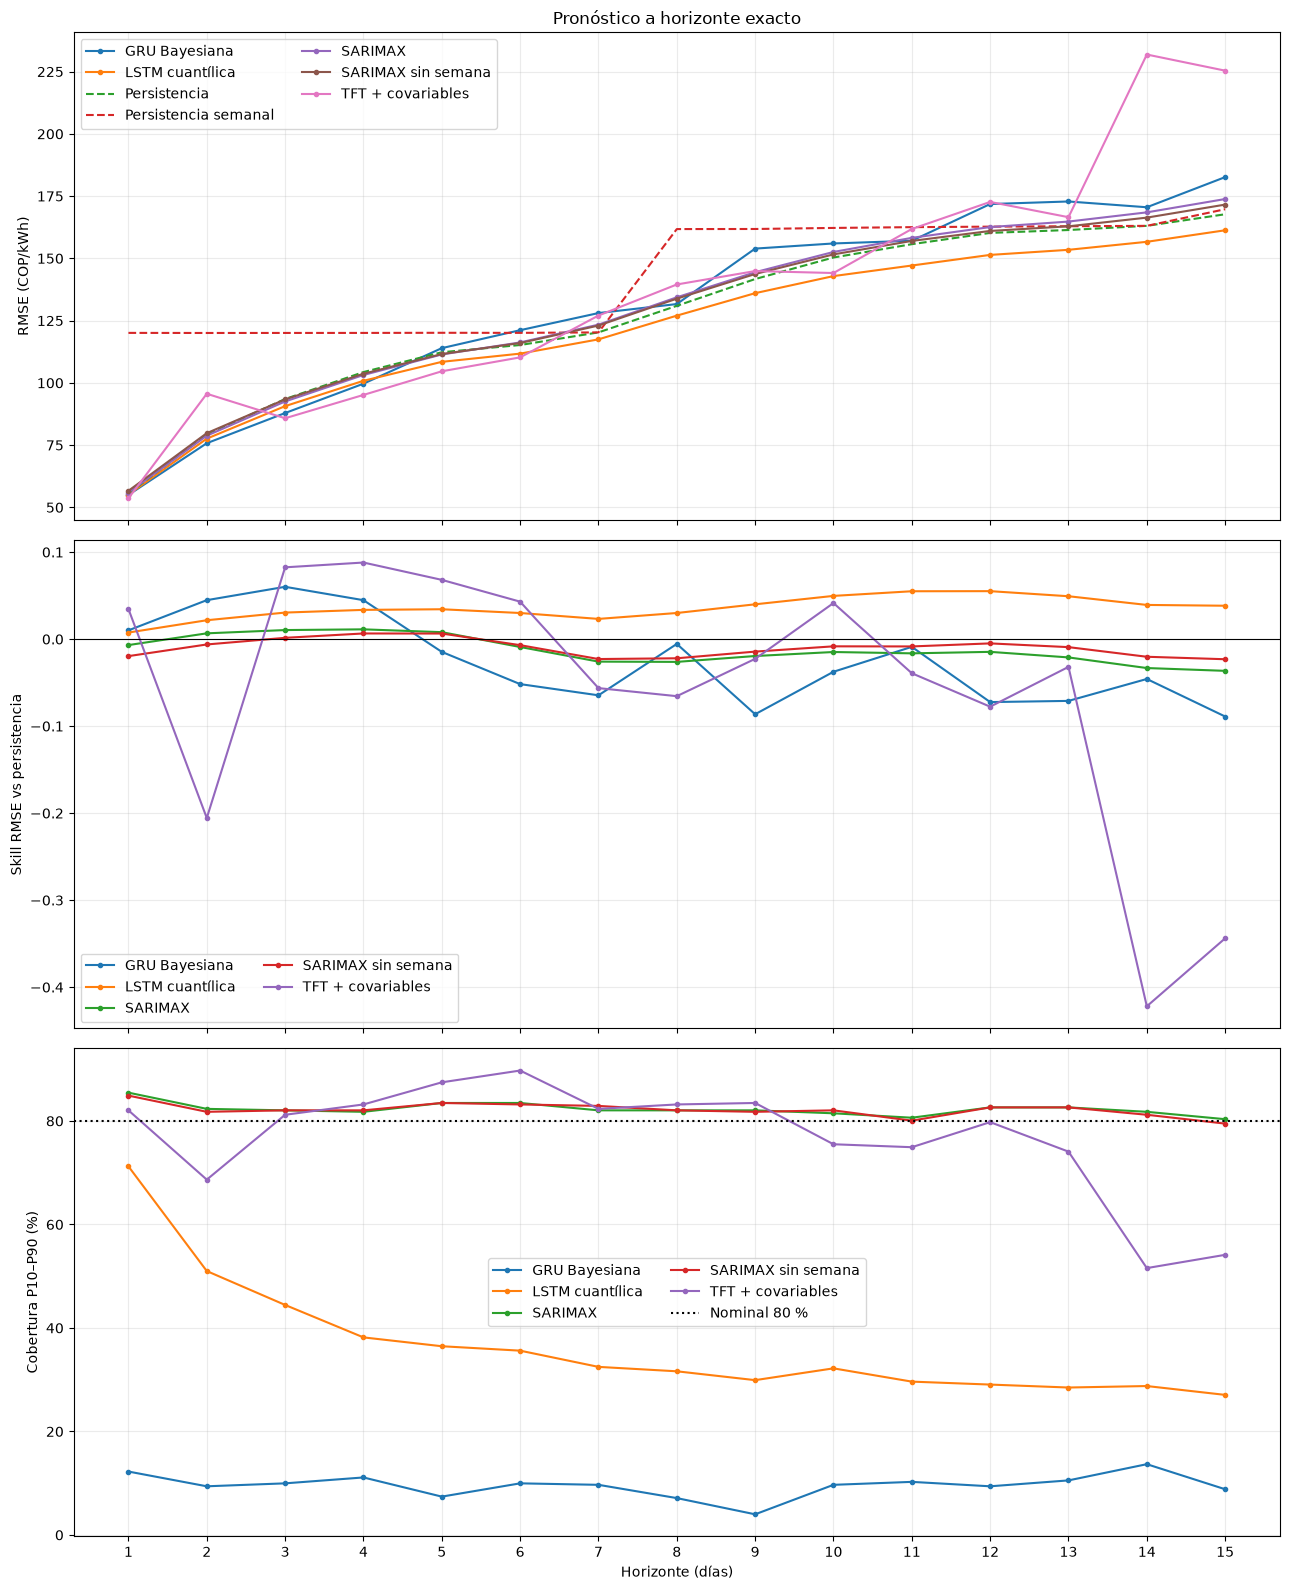

SARIMAX semanal menos SARIMAX sin semana (positivo = sin semana mejor):


Horizonte
1    -0.71
2    -1.01
3    -0.83
4    -0.50
5    -0.18
6     0.24
7     0.36
8     0.54
9     0.72
10    0.98
11    1.24
12    1.56
13    1.91
14    2.11
15    2.24
Name: Diferencia RMSE, dtype: float64

Resultados: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_definitiva_horizontes_exactos


In [11]:
import matplotlib.pyplot as plt
principal=tabla_final[~tabla_final.Modelo.str.contains('oracle')].copy()
fig,axs=plt.subplots(3,1,figsize=(13,16),sharex=True)
for m,g in principal.groupby('Modelo'):
    if m in ['Persistencia','Persistencia semanal']:
        axs[0].plot(g.Horizonte,g.RMSE,ls='--',label=m)
    else:
        axs[0].plot(g.Horizonte,g.RMSE,marker='o',ms=3,label=m)
axs[0].set_ylabel('RMSE (COP/kWh)');axs[0].set_title('Pronóstico a horizonte exacto');axs[0].legend(ncol=2)
ref=principal[principal.Modelo=='Persistencia'].set_index('Horizonte')['RMSE']
for m,g in principal.groupby('Modelo'):
    if m in ['Persistencia','Persistencia semanal']:continue
    axs[1].plot(g.Horizonte,1-g.RMSE.values/ref.loc[g.Horizonte].values,marker='o',ms=3,label=m)
axs[1].axhline(0,color='black',lw=.8);axs[1].set_ylabel('Skill RMSE vs persistencia');axs[1].legend(ncol=2)
for m,g in principal.dropna(subset=['Cobertura 80% (%)']).groupby('Modelo'):
    axs[2].plot(g.Horizonte,g['Cobertura 80% (%)'],marker='o',ms=3,label=m)
axs[2].axhline(80,color='black',ls=':',label='Nominal 80 %')
axs[2].set_ylabel('Cobertura P10–P90 (%)');axs[2].set_xlabel('Horizonte (días)');axs[2].legend(ncol=2)
for ax in axs:ax.grid(alpha=.25);ax.set_xticks(HORIZONTES)
plt.tight_layout();plt.savefig(REPORTS/'curvas_horizontes_exactos.png',dpi=180,bbox_inches='tight');plt.show()

p=principal.pivot(index='Horizonte',columns='Modelo',values='RMSE')
print('SARIMAX semanal menos SARIMAX sin semana (positivo = sin semana mejor):')
display((p['SARIMAX']-p['SARIMAX sin semana']).round(2).rename('Diferencia RMSE'))
print('Resultados:',REPORTS)


## Interpretación y límites

1. Una mejora puntual en h=7 o h=14 **no prueba** estacionalidad: comparar el SARIMAX con y sin componente semanal, contra persistencia semanal y la ACF del entrenamiento.
2. El escenario principal congela covariables futuras para SARIMAX y TFT; no es equivalente a disponer de pronósticos exógenos operativos. El escenario `oracle` es únicamente un límite condicionado y no debe mezclarse en el ranking operativo.
3. La comparación no es perfectamente homogénea en el **mecanismo probabilístico**: SARIMAX usa distribución predictiva paramétrica, TFT cuantiles nativos, LSTM cuantiles plug-in y GRU muestras de pesos. Reportar cobertura y ancho, sin interpretar los cuatro como distribuciones equivalentes.
4. La convergencia de SARIMAX es una **condición de parada**. Si falla, no se calculan rankings sobre ajustes dudosos.
5. Para una tesis definitiva, cualquier recalibración o selección adicional debe hacerse en validación previa al test. **No ajustar con estos resultados del test.**
